In [1]:
# ============================================
# 🔹 Deep Learning using Sequential Model
# 🔹 California Housing Dataset
# 🔹 Easy to Understand Layer Setup
# ============================================

# Step 1: Import Libraries
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Step 2: Load Dataset
data = fetch_california_housing()
X = data.data   # Input features
y = data.target # Output (house price)

# Step 3: Normalize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 4: Split into Train/Test sets
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Step 5: Calculate neurons using formulas
Ni = X_train.shape[1]  # Number of input features
No = 1                 # One output (price)
Nh_min = int((Ni + No) / 2)
Nh_max = int(2 * Ni + No)

print(f"Input features (Ni): {Ni}")
print(f"Output neurons (No): {No}")
print(f"Hidden layer min neurons: {Nh_min}")
print(f"Hidden layer max neurons: {Nh_max}")

# Step 6: Build the Sequential Model
model = Sequential()

# Input Layer + First Hidden Layer (max neurons)
model.add(Dense(Nh_max, input_dim=Ni, activation='relu'))
# Second Hidden Layer (half of first)
model.add(Dense(int(Nh_max / 2), activation='relu'))
# Third Hidden Layer (minimum neurons)
model.add(Dense(Nh_min, activation='relu'))
# Output Layer (1 neuron for price)
model.add(Dense(No))

# Step 7: Compile Model
model.compile(optimizer='adam', loss='mse', metrics=['mae'])

# Step 8: Train the Model
history = model.fit(X_train, y_train, epochs=50, batch_size=32,
                    validation_split=0.2, verbose=1)

# Step 9: Evaluate Model on Test Data
loss, mae = model.evaluate(X_test, y_test, verbose=1)
print(f"\n✅ Test Mean Absolute Error (MAE): {mae:.4f}")

# Optional: Step 10 — Print model summary
print("\nModel Summary:")
model.summary()


Input features (Ni): 8
Output neurons (No): 1
Hidden layer min neurons: 4
Hidden layer max neurons: 17


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/50
413/413 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - loss: 2.0165 - mae: 1.0166 - val_loss: 0.5810 - val_mae: 0.5423
Epoch 2/50
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4828 - mae: 0.5000 - val_loss: 0.4480 - val_mae: 0.4703
Epoch 3/50
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4003 - mae: 0.4525 - val_loss: 0.4204 - val_mae: 0.4665
Epoch 4/50
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3705 - mae: 0.4355 - val_loss: 0.4088 - val_mae: 0.4493
Epoch 5/50
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3633 - mae: 0.4310 - val_loss: 0.3978 - val_mae: 0.4484
Epoch 6/50
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3604 - mae: 0.4281 - val_loss: 0.3892 - val_mae: 0.4404
Epoch 7/50
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3441 - mae: 0.4211 - val_loss: 0.3843 - val_mae: 0.4393
Epoch 8/50
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.3354 - mae: 0.4157 - val_loss: 0.3833 - val_mae: 0.4391
Epoch 9/50
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - lo

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 17)             │           153 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,016 (3.97 KB)

 Trainable params: 338 (1.32 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 678 (2.65 KB)

In [2]:
# Import Libraries
import numpy as np
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# Load Dataset (large dataset)
data = fetch_california_housing()
X, y = data.data, data.target

# Split Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Normalize Data (very important for MSE)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Define input/output
Ni = X_train.shape[1]  # 8 input features
No = 1
Nh_min = int((Ni + No) / 2)
Nh_max = int(2 * Ni + No)

# Define Sequential Model
model = Sequential([
    Input(shape=(Ni,)),
    Dense(Nh_max, activation='relu'),
    Dropout(0.2),                     # helps prevent overfitting
    Dense(Ni * 2, activation='relu'),
    Dense(Ni, activation='relu'),
    Dense(Nh_min, activation='relu'),
    Dense(No, activation='linear')    # output for regression
])

# Compile Model
optimizer = Adam(learning_rate=0.0005)  # smaller LR for smoother training
model.compile(optimizer=optimizer,
              loss='mse',
              metrics=['mae'])

# Early Stopping (stops when val_loss stops improving)
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Train Model
history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=200,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

# Evaluate
test_loss, test_mae = model.evaluate(X_test, y_test, verbose=0)
print(f"\n✅ Final Test MSE: {test_loss:.4f}")
print(f"✅ Final Test MAE: {test_mae:.4f}")

# Model Summary
model.summary()


Epoch 1/200
207/207 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - loss: 6.1351 - mae: 2.1758 - val_loss: 5.3047 - val_mae: 1.9858
Epoch 2/200
207/207 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 5.1587 - mae: 1.9527 - val_loss: 4.9089 - val_mae: 1.8825
Epoch 3/200
207/207 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 4.7085 - mae: 1.8473 - val_loss: 4.5525 - val_mae: 1.7856
Epoch 4/200
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 4.3539 - mae: 1.7454 - val_loss: 4.2239 - val_mae: 1.6913
Epoch 5/200
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 4.1002 - mae: 1.6636 - val_loss: 3.9201 - val_mae: 1.5999
Epoch 6/200
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 3.8500 - mae: 1.5789 - val_loss: 3.6389 - val_mae: 1.5124
Epoch 7/200
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 3.5200 - mae: 1.4849 - val_loss: 3.3800 - val_mae: 1.4305
Epoch 8/200
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 3.3145 - mae: 1.4187 - val_loss: 3.1434 - val_mae: 1.3551
Epoch 9/200
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 4m

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 17)             │           153 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 17)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 16)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,856 (7.25 KB)

 Trainable params: 618 (2.41 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,238 (4.84 KB)

Epoch 1/300


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


516/516 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.7266 - mae: 0.5717 - val_loss: 0.4217 - val_mae: 0.4396 - learning_rate: 0.0010
Epoch 2/300
516/516 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.5184 - mae: 0.4535 - val_loss: 0.3817 - val_mae: 0.3996 - learning_rate: 0.0010
Epoch 3/300
516/516 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.4276 - mae: 0.4353 - val_loss: 0.3607 - val_mae: 0.3907 - learning_rate: 0.0010
Epoch 4/300
516/516 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4275 - mae: 0.4181 - val_loss: 0.3456 - val_mae: 0.3845 - learning_rate: 0.0010
Epoch 5/300
516/516 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3791 - mae: 0.3993 - val_loss: 0.3338 - val_mae: 0.3785 - learning_rate: 0.0010
Epoch 6/300
516/516 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3800 - mae: 0.4031 - val_loss: 0.3276 - val_mae: 0.3647 - learning_rate: 0.0010
Epoch 7/300
516/516 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3508 - mae: 0.3897 - val_loss: 0.3276 - val_mae: 0.3741 - learning_rate: 0.0010
Epoch 8/300

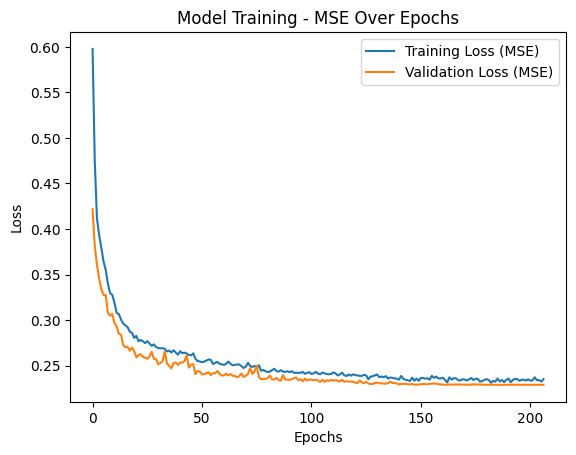

In [3]:
# -----------------------------
# 🧠 Deep Learning Regression Example
# California Housing Dataset (High Data)
# Optimized to minimize MSE
# -----------------------------

# 📦 Import Libraries
import numpy as np
import tensorflow as tf
from tensorflow.keras import models, layers, callbacks, optimizers, regularizers
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

# -----------------------------
# 🧮 Load Dataset
# -----------------------------
data = fetch_california_housing()
X, y = data.data, data.target  # Input features and target

# Split into training and testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# -----------------------------
# ⚖️ Normalize Data
# -----------------------------
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

# y must be reshaped for scaling
y_train_scaled = scaler_y.fit_transform(y_train.reshape(-1, 1))
y_test_scaled = scaler_y.transform(y_test.reshape(-1, 1))

# -----------------------------
# 🧱 Build Sequential Model
# -----------------------------
model = models.Sequential([
    layers.Dense(64, activation='relu', input_shape=(X_train.shape[1],), kernel_regularizer=regularizers.l2(0.001)),
    layers.Dropout(0.2),

    layers.Dense(32, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.Dropout(0.2),

    layers.Dense(16, activation='relu', kernel_regularizer=regularizers.l2(0.001)),

    layers.Dense(1)  # Output layer (for regression)
])

# -----------------------------
# ⚙️ Compile Model
# -----------------------------
optimizer = optimizers.Adam(learning_rate=0.001)
model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])

# -----------------------------
# 🕒 Define Callbacks
# -----------------------------
early_stop = callbacks.EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)
reduce_lr = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=10, min_lr=1e-6)

# -----------------------------
# 🚀 Train Model
# -----------------------------
history = model.fit(
    X_train_scaled, y_train_scaled,
    validation_data=(X_test_scaled, y_test_scaled),
    epochs=300,
    batch_size=32,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

# -----------------------------
# 📉 Evaluate Model
# -----------------------------
mse, mae = model.evaluate(X_test_scaled, y_test_scaled)
print(f"\n✅ Final MSE (scaled): {mse:.4f}, MAE (scaled): {mae:.4f}")

# -----------------------------
# 🔁 Predict and Invert Scaling
# -----------------------------
y_pred_scaled = model.predict(X_test_scaled)
y_pred = scaler_y.inverse_transform(y_pred_scaled)
y_true = scaler_y.inverse_transform(y_test_scaled)

# -----------------------------
# 📊 Final Metrics
# -----------------------------
final_mse = mean_squared_error(y_true, y_pred)
final_mae = mean_absolute_error(y_true, y_pred)

print(f"🏁 Final MSE (real scale): {final_mse:.4f}")
print(f"🏁 Final MAE (real scale): {final_mae:.4f}")

# -----------------------------
# 📈 Optional: Plot Training
# -----------------------------
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='Training Loss (MSE)')
plt.plot(history.history['val_loss'], label='Validation Loss (MSE)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Model Training - MSE Over Epochs')
plt.legend()
plt.show()
